# Домашнее задание 3. Логистическая регрессия и Streamlit

## Описание

В этом задании вы реализуете логистическую регрессию своими руками, разберётесь с метриками качества классификации на реальных несбалансированных данных и упакуете итоговую модель в интерактивное веб-приложение на Streamlit.

- Первая часть посвящена реализации логистической регрессии с помощью градиентного и стохастического градиентного спуска.
- Вторая часть посвящена метрикам классификации: матрице ошибок, precision, recall, $F_\beta$, ROC- и PR-кривым, выбору порога.
- Третья часть посвящена работе с несбалансированными классами.
- Четвертая часть посвящена созданию демонстрации на Streamlit.

**Максимальный балл за задание: 10** (по 2.5 балла за каждую из четырёх частей).

## Общие требования к ДЗ-3

- Для каждого задания приведите код решения.
- Там, где требуется интерпретация, добавьте короткий текстовый вывод.
- Следите за тем, чтобы ноутбук выполнялся последовательно сверху вниз.
- Везде, где есть случайность, фиксируйте `random_state=42`.
- Тестовая выборка используется **только** для финальной оценки качества. Всё, что «подбирается» (гиперпараметры, порог, ресемплинг, параметры масштабирования), подбирается по тренировочной выборке.

> В каждой части оцениваются как код, так и ответы на вопросы. Если отсутствует одно из двух, часть баллов за соответствующее задание может быть снижена.

In [1]:
from importlib.util import find_spec

if find_spec('imblearn') is None:
    %pip install imbalanced-learn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

sns.set_style('darkgrid')
RANDOM_STATE = 42

## <font color="green">Часть 1. Логистическая регрессия своими руками (2.5 балла)</font>

На лекции мы получили функцию потерь логистической регрессии из метода максимума правдоподобия. Если $p_i = \sigma(\langle w, x_i \rangle)$ – предсказанная вероятность класса 1 для $i$-го объекта, то

$$Q(w) = -\frac{1}{\ell}\sum_{i=1}^{\ell}\Big(y_i \log p_i + (1 - y_i)\log(1 - p_i)\Big) \to \min_w, \qquad \sigma(z) = \frac{1}{1 + e^{-z}}.$$

Явной формулы для минимума, как у МНК, здесь нет, поэтому веса ищем градиентным спуском – так же, как на семинаре 3 для линейной регрессии.

**Подсказка.** Сначала выведите градиент $\nabla Q(w)$ на бумаге и запишите его в матричном виде через $X$, $y$ и вектор вероятностей $p$. Вывод градиента приводить в ноутбуке не обязательно, но на защите его могут попросить.

### Задание 1.1. Класс `LogReg` (1.5 балла)

Реализуйте класс логистической регрессии, обучаемой с помощью:
- **полного градиентного спуска** – `gd_type='full'` (1 балл);
- **стохастического градиентного спуска** – `gd_type='stochastic'`: на каждой итерации градиент оценивается по случайному батчу из `batch_size` объектов, как в функции `calc_grad_on_batch` с семинара 3 (0.5 балла).

**Требования:**
- Градиентный спуск записан в векторном виде. Циклы средствами Python допускаются **только** по итерациям градиентного спуска.
- Свободный член $w_0$ учитывается так, как на лекции: внутри `fit` и `predict_proba` к матрице признаков добавляется фиктивный признак $x_0 = 1$ (первым столбцом). Таким образом, `self.w` имеет размер `d + 1`, и `self.w[0]` – это свободный член.
- Критерии остановки (одновременно):
  - L2 норма разности весов на двух соседних итерациях меньше `tolerance`;
  - достигнуто максимальное число итераций `max_iter`.
- Атрибут `loss_history` после вызова `fit` содержит значение функции потерь **на всей обучающей выборке** для каждой итерации, начиная с первой (до совершения первого шага по антиградиенту).
- Веса инициализируются вектором `w0`, если он передан, иначе – нулевым вектором.
- `predict_proba` возвращает массив размера `(N, 2)`: в первом столбце вероятность класса 0, во втором – класса 1 (как в `sklearn`).
- `predict` возвращает метки классов `0/1`, сравнивая вероятность класса 1 с порогом `threshold`.
- При вычислении логарифма в `calc_loss` позаботьтесь о вычислительной устойчивости: $\log 0$ давать не должно (например, используйте `np.clip`).

Полезно [почитать](https://scikit-learn.org/stable/developers/develop.html) о том, как устроены модели в `sklearn`.

**ВАЖНО!** Заполните шаблон ниже, не меняя структуру класса и сигнатуры методов. Добавлять свои вспомогательные методы можно.

In [ ]:
class LogReg(BaseEstimator, ClassifierMixin):
    def __init__(self, gd_type='full', tolerance=1e-4, max_iter=1000,
                 w0=None, eta=1e-2, batch_size=32, random_state=42):
        """
        gd_type: 'full' или 'stochastic'
        tolerance: порог для критерия останова по норме разности весов
        max_iter: максимальное число итераций градиентного спуска
        w0: np.array размера (d + 1) - начальные веса (w0[0] - свободный член)
        eta: длина шага (learning rate)
        batch_size: размер батча для стохастического градиентного спуска
        random_state: seed для выбора батчей
        """
        self.gd_type = gd_type
        self.tolerance = tolerance
        self.max_iter = max_iter
        self.w0 = w0
        self.eta = eta
        self.batch_size = batch_size
        self.random_state = random_state

    def fit(self, X, y):
        """
        X: np.array размера (N, d)
        y: np.array размера (N) из 0 и 1
        ---
        output: self
        """
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        self.classes_ = np.array([0, 1])
        self.loss_history = []
        rng = np.random.default_rng(self.random_state)

        X = np.column_stack((np.ones(X.shape[0]), X))
        self.w = (np.zeros(X.shape[1]) if self.w0 is None
                  else np.array(self.w0, dtype=float, copy=True))

        for _ in range(self.max_iter):
            self.loss_history.append(self.calc_loss(X, y))
            if self.gd_type == 'stochastic':
                indices = rng.integers(X.shape[0], size=self.batch_size)
                gradient = self.calc_gradient(X[indices], y[indices])
            else:
                gradient = self.calc_gradient(X, y)

            next_weights = self.w - self.eta * gradient
            weight_change = np.linalg.norm(next_weights - self.w)
            self.w = next_weights
            if weight_change < self.tolerance:
                break

        return self

    def sigmoid(self, z):
        return np.exp(-np.logaddexp(0.0, -z))

    def predict_proba(self, X):
        """
        X: np.array размера (N, d)
        ---
        output: np.array размера (N, 2)
        """
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')

        X = np.asarray(X, dtype=float)
        X = np.column_stack((np.ones(X.shape[0]), X))
        probabilities = self.sigmoid(X @ self.w)
        return np.column_stack((1.0 - probabilities, probabilities))

    def predict(self, X, threshold=0.5):
        """
        X: np.array размера (N, d)
        ---
        output: np.array размера (N) из 0 и 1
        """
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')

        probabilities = self.predict_proba(X)[:, 1]
        return (probabilities > threshold).astype(int)

    def calc_gradient(self, X, y):
        """
        X: np.array размера (N, d + 1) - уже с фиктивным признаком
           (N может быть равно batch_size при стохастическом спуске)
        y: np.array размера (N)
        ---
        output: np.array размера (d + 1) - градиент log-loss по self.w
        """
        probabilities = self.sigmoid(X @ self.w)
        return X.T @ (probabilities - y) / X.shape[0]

    def calc_loss(self, X, y):
        """
        X: np.array размера (N, d + 1) - уже с фиктивным признаком
        y: np.array размера (N)
        ---
        output: float - значение log-loss при текущих self.w
        """
        scores = X @ self.w
        negative_margin = np.where(y == 1, -scores, scores)
        return np.logaddexp(0.0, negative_margin).mean()

Ячейка ниже проверяет вашу реализацию градиента численно: сравнивает `calc_gradient` с конечными разностями функции `calc_loss`. Она не оценивается, но если проверка не проходит – ищите ошибку, прежде чем идти дальше.

In [ ]:
def check_gradient(model, d=5, N=50, eps=1e-6, seed=0):
    rng = np.random.default_rng(seed)
    X = np.hstack([np.ones((N, 1)), rng.normal(size=(N, d))])
    y = rng.integers(0, 2, size=N).astype(float)
    model.w = rng.normal(size=d + 1)

    analytic = model.calc_gradient(X, y)
    numeric = np.zeros(d + 1)
    w = model.w.copy()
    for j in range(d + 1):
        e = np.zeros(d + 1)
        e[j] = eps
        model.w = w + e
        loss_plus = model.calc_loss(X, y)
        model.w = w - e
        loss_minus = model.calc_loss(X, y)
        numeric[j] = (loss_plus - loss_minus) / (2 * eps)
    model.w = w
    return np.max(np.abs(analytic - numeric))


err = check_gradient(LogReg())
print(f'max |analytic - numeric| = {err:.2e}')
assert err < 1e-5, 'Градиент не совпадает с численным - проверьте calc_gradient и calc_loss'

max |analytic - numeric| = 1.44e-10


Теперь проверим работу класса на синтетических данных.

In [5]:
X, y = make_classification(
    n_samples=20000, n_features=20, n_informative=5,
    random_state=RANDOM_STATE)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

### Задание 1.2. Обучение и сходимость (0.25 балла)

1. Обучите две модели: `LogReg(gd_type='full')` и `LogReg(gd_type='stochastic')` с параметрами по умолчанию.
2. Для каждой модели выведите число сделанных итераций и постройте на одном графике `loss_history` обеих моделей.
3. Ответьте на вопросы:
   - По какому критерию остановилась каждая модель – по `tolerance` или по `max_iter`?
   - Почему стохастическому спуску с постоянным шагом трудно остановиться по критерию `tolerance`?
   - Чем отличаются графики функции потерь?
   - Сколько объектов «просматривает» за одну итерацию каждый из методов?

Полный спуск: 1000 итераций
Стохастический спуск: 1000 итераций


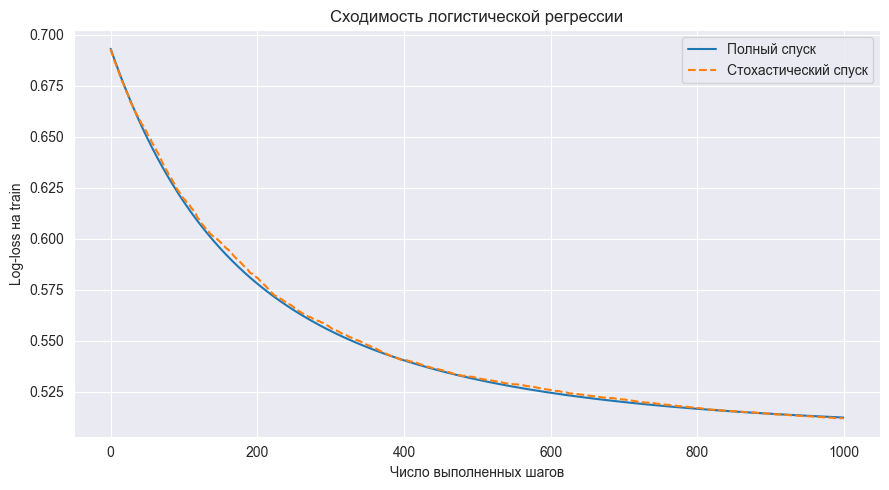

In [6]:
full_model = LogReg(gd_type='full').fit(X_train, y_train)
stochastic_model = LogReg(gd_type='stochastic').fit(X_train, y_train)

fig, ax = plt.subplots(figsize=(9, 5))
for label, model, linestyle in (
    ('Полный спуск', full_model, '-'),
    ('Стохастический спуск', stochastic_model, '--'),
):
    print(f'{label}: {len(model.loss_history)} итераций')
    ax.plot(model.loss_history, label=label, linestyle=linestyle)

ax.set(
    xlabel='Число выполненных шагов',
    ylabel='Log-loss на train',
    title='Сходимость логистической регрессии',
)
ax.legend()
fig.tight_layout()
plt.show()

1. Оба режима сделали 1000 итераций и остановились по max_iter. На последнем шаге L2-норма изменения весов была около 0,000399 у полного спуска и 0,003055 у стохастического, оба значения выше tolerance = 0.0001.
2. На каждом шаге выбирается новый случайный батч следовательно даже вблизи минимума градиент по отдельному батчу может быть заметным. а при постоянной длине шага веса продолжают колебаться.
3. У полного спуска ошибка плавно убывала, у стохастического она в целом уменьшалась, но иногда подскакивала
4. Полный спуск считает градиент по всем строкам, стохастический считает градиент по 32 случайно выбранным строкам с возвращением

### Задание 1.3. Длина шага (0.25 балла)

Для полного градиентного спуска обучите модели с сеткой `eta` из списка `[1e-3, 1e-2, 1e-1, 1, 10]` и постройте графики `loss_history` (удобно в логарифмической шкале по оси `x`). Выведите для каждого `eta` финальное значение функции потерь и число итераций.

Как длина шага влияет на скорость и качество сходимости? Есть ли значения `eta`, при которых спуск ведёт себя плохо?

,Итерации,Итоговый log-loss
eta,,
0.001,1000,0.618087
0.010,1000,0.512435
0.100,465,0.505762
1.000,70,0.505757
10.000,1000,0.901345


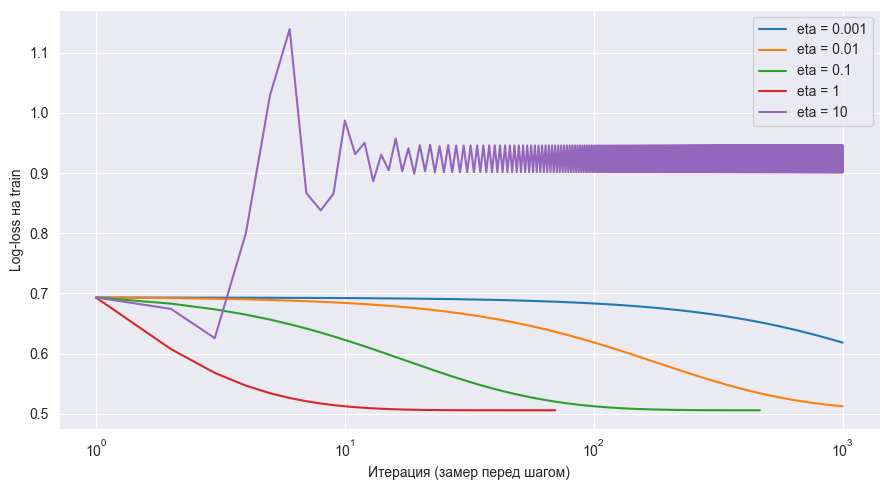

In [7]:
eta_results = []
fig, ax = plt.subplots(figsize=(9, 5))

for eta in [1e-3, 1e-2, 1e-1, 1, 10]:
    model = LogReg(gd_type='full', eta=eta).fit(X_train, y_train)
    history = model.loss_history
    final_loss = model.calc_loss(
        np.column_stack((np.ones(len(X_train)), X_train)), y_train
    )
    eta_results.append({'eta': eta, 'Итерации': len(history), 'Итоговый log-loss': final_loss})
    ax.plot(np.arange(1, len(history) + 1), history, label=f'eta = {eta:g}')

eta_table = pd.DataFrame(eta_results).set_index('eta')
display(eta_table.round(6))
ax.set(xscale='log', xlabel='Итерация (замер перед шагом)', ylabel='Log-loss на train')
ax.legend()
fig.tight_layout()
plt.show()

При n =0.001 и 0.01 за 1000 шагов ошибка осталась выше лучшего результата в сетке. При n=0.1 ошибка дошла до 0,5058 за 465 шагов. При n=1 получили ту же ошибку с точностью до четырёх знаков за 70 шагов. При n=10 спуск перескакивает через область минимума, ошибка колеблется и в конце равна 0,9013.

### Задание 1.4. Сравнение с `sklearn` (0.5 балла)

1. Обучите `LogisticRegression` из `sklearn` с параметрами по умолчанию.
2. Для трёх моделей (ваш GD, ваш SGD, `sklearn`) посчитайте на тестовой выборке accuracy и ROC-AUC и сведите их в таблицу `pd.DataFrame`.
3. Сравните веса вашей модели (GD) с весами модели `sklearn` (`intercept_` и `coef_`).

Ответьте на вопросы:
   - Совпадают ли метрики? Совпадают ли веса?
   - Что в модели `sklearn` по умолчанию делает её не равной вашей? Найдите ответ в [документации](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html). Как настроить `LogisticRegression`, чтобы она решала ту же задачу оптимизации, что и ваша модель?

In [8]:
sklearn_model = LogisticRegression().fit(X_train, y_train)
comparison_models = {
    'LogReg GD': full_model,
    'LogReg SGD': stochastic_model,
    'sklearn': sklearn_model,
}
comparison_table = pd.DataFrame.from_dict({
    name: {
        'accuracy': metrics.accuracy_score(y_test, model.predict(X_test)),
        'ROC-AUC': metrics.roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]),
    }
    for name, model in comparison_models.items()
}, orient='index')
display(comparison_table.round(6))

weight_comparison = pd.DataFrame({
    'LogReg GD': full_model.w,
    'sklearn': np.r_[sklearn_model.intercept_, sklearn_model.coef_.ravel()],
}, index=['intercept'] + [f'x{i}' for i in range(1, X_train.shape[1] + 1)])
display(weight_comparison.round(6))

/Users/zuevakim/Documents/Codex/2026-11-07/ghb/work/hw3-full/venv312/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


,accuracy,ROC-AUC
LogReg GD,0.7820,0.838787
LogReg SGD,0.7825,0.838830
sklearn,0.7765,0.838676


,LogReg GD,sklearn
intercept,-0.002114,-0.021880
x1,0.006076,0.002741
x2,0.006963,0.009039
x3,-0.547170,-0.722690
x4,-0.144536,-0.262335
x5,0.012487,0.016588
x6,-0.006325,-0.011488
x7,0.000814,0.005587
x8,0.039084,0.057188
x9,-0.002425,-0.001239


ROC-AUC у трёх моделей близок к 0,839. accuracy GD, SGD и sklearn равна 78,20%, 78,25% и 77,65%. Свободные члены GD и sklearn равны -0,0021 и -0,0219. Коэффициенты тоже отличаются.

По умолчанию sklearn добавляет L2-штраф к log-loss и использует решатель L-BFGS. Параметр penalty=None убирает штраф, и целевая функция совпадает с нашей. Критерии остановки и алгоритмы оптимизации могут дать разные приближённые веса. [Документация LogisticRegression](https://scikit-learn.org/1.6/modules/generated/sklearn.linear_model.LogisticRegression.html)


## <font color="green">Часть 2. Метрики классификации (2.5 балла)</font>

### Данные

Используем датасет [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality) (P. Cortez et al., 2009, лицензия CC BY 4.0).
Каждая строка – образец португальского вина: 11 физико-химических характеристик и признак `is_red` (1 - красное, 0 - белое). Эксперты оценили каждое вино по шкале от 0 до 10. Мы превратили оценку в бинарную целевую переменную:

- `target = 1` – «хорошее» вино (оценка не ниже 7);
- `target = 0` – все остальные.

**Сценарий.** Сервис по подписке каждый месяц рекомендует клиентам вина. Модель должна по результатам лабораторного анализа отбирать «хорошие» вина в подборку. Рекомендовать клиенту посредственное вино - плохо (клиент разочаруется), но и пропускать хорошие вина тоже не хочется (подборка получится скудной).

In [9]:
from pathlib import Path

data_path = Path('Data/wine_quality.csv')
data_url = ('https://raw.githubusercontent.com/paiflare/ml_hse_2026/'
            'refs/heads/master/homework/hw_3/Data/wine_quality.csv')
df = pd.read_csv(data_path if data_path.is_file() else data_url)

print('Data shape:', df.shape)
df.head()

Data shape: (6497, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,is_red,target
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,1,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,1,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,1,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0


In [10]:
clean_df = df.drop_duplicates()
X = clean_df.drop(columns='target')
y = clean_df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (3724, 12)  Test: (1596, 12)


### Задание 2.1. Первичный анализ и accuracy (0.25 балла)

1. Проверьте данные на пропуски и полные дубликаты строк. Нужно ли удалять дубликаты в этой задаче? Посчитайте долю класса 1 (prevalence) в тренировочной и тестовой выборках. Зачем при разбиении был указан параметр `stratify=y`?
2. Посчитайте accuracy на тестовой выборке для константной модели, которая всегда отвечает «не хорошее вино» (класс 0).
3. Обучите пайплайн `make_pipeline(StandardScaler(), LogisticRegression())` и посчитайте его accuracy на тестовой выборке.

Сравните два числа. Почему accuracy плохо подходит для этой задачи?

In [11]:
print('Пропуски:', df.isna().sum().sum())
print('Полные дубликаты сверх первых вхождений:', df.duplicated().sum())
display(pd.Series({'train': y_train.mean(), 'test': y_test.mean()}, name='Доля класса 1').round(4))

constant_predictions = np.zeros(len(y_test), dtype=int)
wine_model = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_train, y_train)
wine_predictions = wine_model.predict(X_test)
display(pd.Series({
    'Всегда 0': metrics.accuracy_score(y_test, constant_predictions),
    'Логистическая регрессия': metrics.accuracy_score(y_test, wine_predictions),
}, name='Accuracy на test').round(4))

Пропуски: 0
Полные дубликаты сверх первых вхождений: 1177


train    0.1896
test     0.1898
Name: Доля класса 1, dtype: float64

/Users/zuevakim/Documents/Codex/2026-11-07/ghb/work/hw3-full/venv312/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


Всегда 0                   0.8102
Логистическая регрессия    0.8152
Name: Accuracy на test, dtype: float64

Пропусков нет. В исходной таблице 1177 полных повторов сверх первых вхождений. Удалил их до разбиения, чтобы одинаковые строки не оказались одновременно в train и test. Стратификация сохранила долю класса 1 примерно одинаковой 18,96% на train и 18,98% на test

Accuracy выросла с 81,02% до 81,52%. Модель всегда 0 уже даёт высокий результат за счёт частого класса, хотя пропускает все хорошие вина. По одной accuracy полноту подборки не видно

### Задание 2.2. Матрица ошибок своими руками (0.5 балла)

Для пайплайна логистической регрессии из задания 2.1 получите предсказания классов на тестовой выборке.

1. Посчитайте TP, TN, FP, FN **без функций из `sklearn.metrics`** – только средствами `numpy`/`pandas`.
2. Сравните результат с `metrics.confusion_matrix` и нарисуйте матрицу ошибок с помощью `metrics.ConfusionMatrixDisplay`.
3. Объясните в терминах сценария, что означают FP и FN в этой задаче. Какая из ошибок модели встречается чаще?

TP=92, TN=1209, FP=84, FN=211


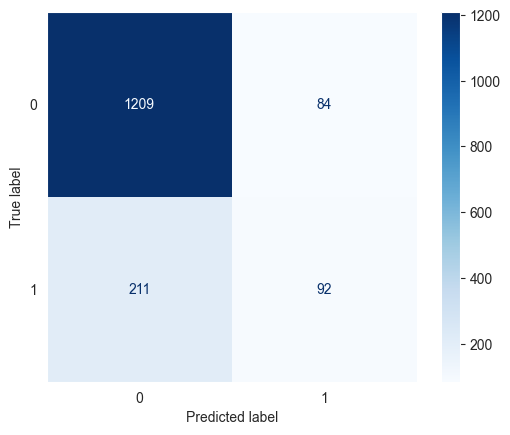

In [12]:
y_true = y_test.to_numpy()
TP = np.count_nonzero((y_true == 1) & (wine_predictions == 1))
TN = np.count_nonzero((y_true == 0) & (wine_predictions == 0))
FP = np.count_nonzero((y_true == 0) & (wine_predictions == 1))
FN = np.count_nonzero((y_true == 1) & (wine_predictions == 0))
print(f'TP={TP}, TN={TN}, FP={FP}, FN={FN}')

manual_matrix = np.array([[TN, FP], [FN, TP]])
sklearn_matrix = metrics.confusion_matrix(y_test, wine_predictions, labels=[0, 1])
np.testing.assert_array_equal(manual_matrix, sklearn_matrix)
matrix_display = metrics.ConfusionMatrixDisplay(sklearn_matrix, display_labels=[0, 1]).plot(cmap='Blues')
matrix_display.ax_.grid(False)
plt.show()

FP - в подборку попало вино с оценкой ниже 7 84 случаев. FN - в подборку не попало вино с оценкой от 7 211 случаев. Модель чаще пропускает хорошие вина.

### Задание 2.3. Precision, recall, $F_\beta$ (0.5 балла)

1. Используя TP, TN, FP, FN из задания 2.2, посчитайте по формулам precision, recall, $F_1$, $F_{0.5}$ и $F_2$:

$$F_{\beta} = (1 + \beta^2)\frac{\text{Precision} \cdot \text{Recall}}{\beta^2 \cdot \text{Precision} + \text{Recall}}.$$

2. Проверьте свои значения с помощью `metrics.precision_score`, `metrics.recall_score`, `metrics.fbeta_score`.
3. Ответьте на вопросы:
   - Что больше ценится в $F_{0.5}$, а что в $F_2$ – precision или recall?
   - Какую из трёх F-мер вы бы выбрали для нашего сценария, если подписчики очень болезненно реагируют на посредственные вина в подборке? А если сервис позиционирует себя как «самая широкая подборка хороших вин»?

In [13]:
precision = TP / (TP + FP) if TP + FP else 0.0
recall = TP / (TP + FN) if TP + FN else 0.0
manual_scores = {'precision': precision, 'recall': recall}
sklearn_scores = {
    'precision': metrics.precision_score(y_test, wine_predictions, zero_division=0),
    'recall': metrics.recall_score(y_test, wine_predictions, zero_division=0),
}

for beta in (0.5, 1, 2):
    denominator = beta**2 * precision + recall
    manual_scores[f'F{beta:g}'] = (
        (1 + beta**2) * precision * recall / denominator if denominator else 0.0
    )
    sklearn_scores[f'F{beta:g}'] = metrics.fbeta_score(
        y_test, wine_predictions, beta=beta, zero_division=0
    )

f_scores = pd.DataFrame({'По формуле': manual_scores, 'sklearn': sklearn_scores})
np.testing.assert_allclose(f_scores['По формуле'], f_scores['sklearn'])
display(f_scores.round(4))

,По формуле,sklearn
precision,0.5227,0.5227
recall,0.3036,0.3036
F0.5,0.4568,0.4568
F1,0.3841,0.3841
F2,0.3314,0.3314


$F_{0.5}$ сильнее учитывает precision. Он подходит, если попадание посредственного вина особенно нежелательно. $F_2$ сильнее учитывает recall и подходит, если цель найти как можно больше хороших вин. $F_1$ даёт обеим метрикам одинаковый вес.

### Задание 2.4. ROC- и PR-кривые (0.5 балла)

Сравним две модели:
- `make_pipeline(StandardScaler(), LogisticRegression())` из `sklearn`;
- ваш `LogReg(gd_type='full')` из части 1 (не забудьте масштабировать признаки, подберите `eta` и `max_iter` так, чтобы спуск сошёлся).

1. Для каждой модели получите на тестовой выборке **непрерывные оценки** (score) – вероятность класса 1.
2. Постройте ROC-кривые двух моделей на одном графике и PR-кривые двух моделей на другом графике. На PR-графике отметьте горизонтальной линией уровень случайной модели.
3. Посчитайте ROC-AUC (`metrics.roc_auc_score`) и PR-AUC (`metrics.average_precision_score`) и сведите в таблицу.
4. Возьмите вероятности $p$ класса 1 модели из `sklearn` и посчитайте ROC-AUC для преобразованных оценок: $10 \cdot p$, $p^3$, $\log\frac{p}{1-p}$, $-p$. Объясните результат.

Ответьте на вопросы:
- Какая модель лучше? Совпадает ли ранжирование моделей по ROC-AUC и по PR-AUC?
- Чему равен PR-AUC случайной модели в этой задаче и почему он не равен 0.5?
- Что получится, если подать в `roc_auc_score` предсказанные метки классов?

LogReg GD: 3809 шагов, лимит 20000


,ROC-AUC,PR-AUC (AP)
sklearn,0.820876,0.484766
LogReg GD,0.820562,0.483764


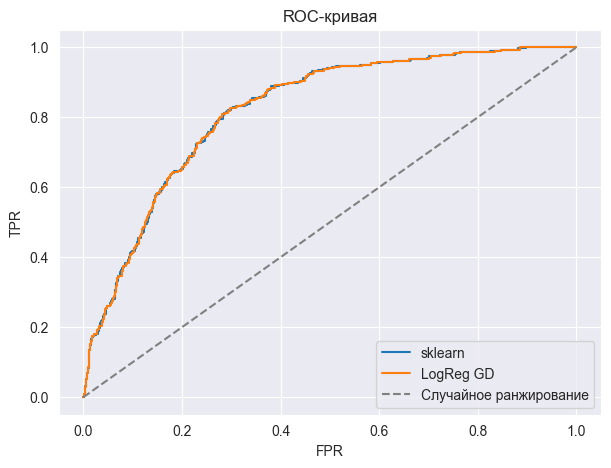

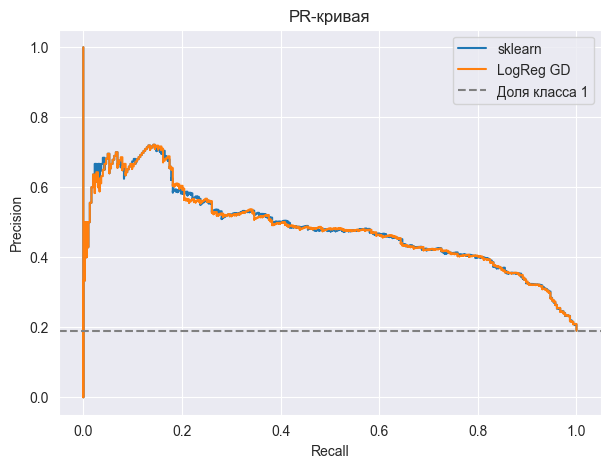

p                       0.820876
10p                     0.820876
p³                      0.820876
log(p / (1 − p))        0.820876
−p                      0.179124
Предсказанные классы    0.619333
Name: ROC-AUC, dtype: float64

In [14]:
wine_scaler = StandardScaler().fit(X_train)
wine_gd = LogReg(gd_type='full', eta=1.0, tolerance=1e-6, max_iter=20000)
wine_gd.fit(wine_scaler.transform(X_train), y_train)
print(f'LogReg GD: {len(wine_gd.loss_history)} шагов, лимит {wine_gd.max_iter}')
wine_scores = wine_model.predict_proba(X_test)[:, 1]
wine_gd_scores = wine_gd.predict_proba(wine_scaler.transform(X_test))[:, 1]

score_sets = {'sklearn': wine_scores, 'LogReg GD': wine_gd_scores}
auc_table = pd.DataFrame.from_dict({
    name: {
        'ROC-AUC': metrics.roc_auc_score(y_test, scores),
        'PR-AUC (AP)': metrics.average_precision_score(y_test, scores),
    }
    for name, scores in score_sets.items()
}, orient='index')
display(auc_table.round(6))

roc_fig, roc_ax = plt.subplots(figsize=(7, 5))
pr_fig, pr_ax = plt.subplots(figsize=(7, 5))
for name, scores in score_sets.items():
    fpr, tpr, _ = metrics.roc_curve(y_test, scores)
    pr_precision, pr_recall, _ = metrics.precision_recall_curve(y_test, scores)
    roc_ax.plot(fpr, tpr, label=name)
    pr_ax.step(pr_recall, pr_precision, where='post', label=name)

roc_ax.plot([0, 1], [0, 1], '--', color='gray', label='Случайное ранжирование')
pr_ax.axhline(y_test.mean(), linestyle='--', color='gray', label='Доля класса 1')
roc_ax.set(xlabel='FPR', ylabel='TPR', title='ROC-кривая')
pr_ax.set(xlabel='Recall', ylabel='Precision', title='PR-кривая')
for ax in (roc_ax, pr_ax):
    ax.legend()
plt.show()

score_transforms = {
    'p': wine_scores,
    '10p': 10 * wine_scores,
    'p³': wine_scores**3,
    'log(p / (1 − p))': np.log(wine_scores) - np.log1p(-wine_scores),
    '−p': -wine_scores,
    'Предсказанные классы': wine_predictions,
}
transformed_auc = pd.Series({
    name: metrics.roc_auc_score(y_test, scores)
    for name, scores in score_transforms.items()
}, name='ROC-AUC')
display(transformed_auc.round(6))

Обе метрики дают один порядок. У sklearn ROC-AUC и AP равны 0,8209 и 0,4848, у LogReg GD - 0,8206 и 0,4838. Разница мала. LogReg GD достиг tolerance за 3809 шагов.

У случайного ранжирования базовый уровень PR равен доле класса 1, здесь это 0,1898. Случайная подборка в среднем сохраняет эту долю хороших вин.

Преобразования $10p$, $p^3$ и логит сохраняют порядок оценок и ROC-AUC. $-p$ разворачивает порядок и даёт $1 - AUC$ (0,1791). Метки 0/1 дают только два уровня ранжирования и много совпадений. ROC-AUC падает до 0,6193 и для таких оценок равен среднему из TPR и TNR при использованном пороге.

### Задание 2.5. Выбор порога (0.75 балла)

Порог 0.5 у логистической регрессии ничем не выделен – его можно и нужно выбирать под задачу. Но подбирать порог на тестовой выборке нельзя: тогда оценка качества на тесте окажется завышенной.

1. Выделите из тренировочной выборки валидационную (`test_size=0.25`, `stratify`, `random_state=42`). Обучите пайплайн логистической регрессии на оставшейся части и получите вероятности на валидации.
2. Постройте на одном графике зависимость precision, recall и $F_1$ на валидации от порога $t \in [0, 1]$.
3. По валидации выберите два порога:
   - $t_{F_1}$ – максимизирующий $F_1$;
   - $t_{R}$ – дающий максимальный precision при условии recall $\ge 0.7$ (сервис хочет, чтобы в подборку попадало не меньше 70% хороших вин).
4. Переобучите пайплайн на всей тренировочной выборке и посчитайте на тестовой выборке precision, recall и $F_1$ при порогах $0.5$, $t_{F_1}$ и $t_{R}$. Сведите результаты в таблицу.

Выполнилось ли на тесте условие recall $\ge 0.7$? Почему порог, подобранный на валидации, не гарантирует выполнения условия на новых данных? Какой порог вы бы выбрали для сценария из описания данных и почему?

/Users/zuevakim/Documents/Codex/2026-11-07/ghb/work/hw3-full/venv312/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


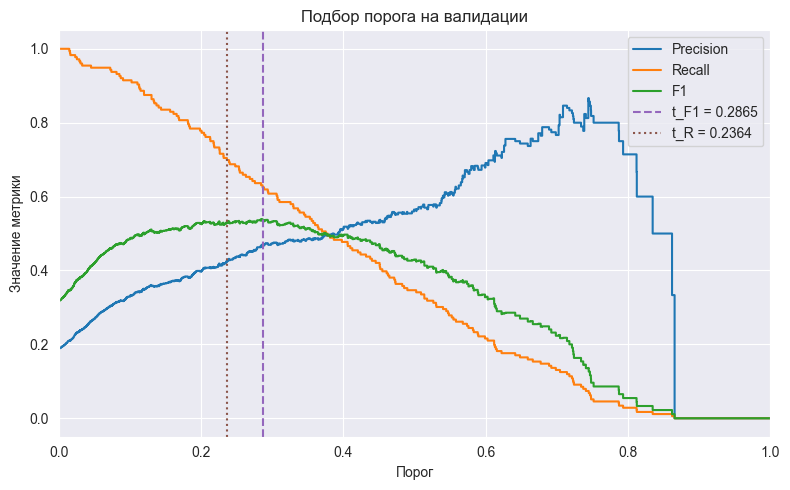

,Порог,precision,recall,F1
t_F1,0.2865,0.4703,0.6307,0.5388
t_R,0.2364,0.4261,0.7045,0.5310


/Users/zuevakim/Documents/Codex/2026-11-07/ghb/work/hw3-full/venv312/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


,Порог,precision,recall,F1
0.5,0.5000,0.5227,0.3036,0.3841
t_F1,0.2865,0.4574,0.6205,0.5266
t_R,0.2364,0.4213,0.7063,0.5277


In [15]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train, random_state=RANDOM_STATE
)
validation_model = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_fit, y_fit)
validation_scores = validation_model.predict_proba(X_val)[:, 1]
val_precision, val_recall, thresholds = metrics.precision_recall_curve(y_val, validation_scores)
val_precision, val_recall = val_precision[:-1], val_recall[:-1]
metric_sum = val_precision + val_recall
val_f1 = np.divide(
    2 * val_precision * val_recall, metric_sum,
    out=np.zeros_like(metric_sum), where=metric_sum > 0,
)

best_f1_index = np.argmax(val_f1)
eligible_indices = np.flatnonzero(val_recall >= 0.7)
best_recall_index = eligible_indices[np.argmax(val_precision[eligible_indices])]
t_f1 = thresholds[best_f1_index]
t_recall = thresholds[best_recall_index]

fig, ax = plt.subplots(figsize=(8, 5))
for name, values in [('Precision', val_precision), ('Recall', val_recall), ('F1', val_f1)]:
    ax.step(np.r_[0, thresholds, 1], np.r_[values[0], values, 0], where='pre', label=name)
ax.axvline(t_f1, linestyle='--', color='tab:purple', label=f't_F1 = {t_f1:.4f}')
ax.axvline(t_recall, linestyle=':', color='tab:brown', label=f't_R = {t_recall:.4f}')
ax.set(xlim=(0, 1), xlabel='Порог', ylabel='Значение метрики', title='Подбор порога на валидации')
ax.legend()
fig.tight_layout()
plt.show()

validation_choices = pd.DataFrame({
    'Порог': [t_f1, t_recall],
    'precision': val_precision[[best_f1_index, best_recall_index]],
    'recall': val_recall[[best_f1_index, best_recall_index]],
    'F1': val_f1[[best_f1_index, best_recall_index]],
}, index=['t_F1', 't_R'])
display(validation_choices.round(4))

wine_model.fit(X_train, y_train)
wine_scores = wine_model.predict_proba(X_test)[:, 1]
wine_thresholds = {'0.5': 0.5, 't_F1': t_f1, 't_R': t_recall}
threshold_test_table = pd.DataFrame.from_dict({
    name: {
        'Порог': threshold,
        'precision': metrics.precision_score(y_test, wine_scores >= threshold, zero_division=0),
        'recall': metrics.recall_score(y_test, wine_scores >= threshold, zero_division=0),
        'F1': metrics.f1_score(y_test, wine_scores >= threshold, zero_division=0),
    }
    for name, threshold in wine_thresholds.items()
}, orient='index')
display(threshold_test_table.round(4))

На валидации $t_R=0,2364$ дал recall 0,7045. На test recall равен 0,7063, то есть условие recall ≥ 0,7 выполнено. Порог $t_{F_1}=0,2865$ дал test recall 0,6205.

Recall зависит от набора вин и их оценок модели. Другая выборка и переобучение на всём train могут изменить результат. Для сервиса выбираю $t_R$. Среди порогов, давших recall не ниже 0,7 на валидации, у него максимальная precision.

## <font color="green">Часть 3. Несбалансированные классы (2.5 балла)</font>

Класс «хорошее вино» встречается примерно в 5 раз реже остальных. На семинаре 4 мы обсуждали, что с этим можно сделать:
- задать классам веса (`class_weight='balanced'`);
- сбалансировать обучающую выборку: undersampling, oversampling и их комбинации (библиотека [imbalanced-learn](https://imbalanced-learn.org/stable/)).

Во всех заданиях этой части сравнивайте модели по одному и тому же набору метрик на тестовой выборке: accuracy, precision, recall, $F_1$ (при пороге по умолчанию), ROC-AUC и PR-AUC. Удобно написать для этого одну функцию, которая принимает обученную модель и возвращает строку таблицы.

**Важно:** ресемплинг применяется **только к тренировочной выборке**. Тестовая выборка остаётся нетронутой, иначе метрики перестанут отражать качество на реальном распределении классов.

### Задание 3.1. Веса классов (0.5 балла)

Обучите логистическую регрессию в пайплайне со `StandardScaler` с параметром `class_weight=None` и `class_weight='balanced'`. Сведите метрики двух моделей в таблицу.

1. Какие веса получают объекты классов 0 и 1 при `class_weight='balanced'`? Посчитайте их по формуле из документации `sklearn`.
2. Какие метрики заметно изменились, а какие почти нет? Объясните, почему.

In [16]:
from sklearn.utils.class_weight import compute_class_weight

def evaluate_wine(scores, predictions):
    return {
        'accuracy': metrics.accuracy_score(y_test, predictions),
        'precision': metrics.precision_score(y_test, predictions, zero_division=0),
        'recall': metrics.recall_score(y_test, predictions, zero_division=0),
        'F1': metrics.f1_score(y_test, predictions, zero_division=0),
        'ROC-AUC': metrics.roc_auc_score(y_test, scores),
        'PR-AUC (AP)': metrics.average_precision_score(y_test, scores),
    }

balanced_model = make_pipeline(
    StandardScaler(), LogisticRegression(class_weight='balanced')
).fit(X_train, y_train)
balanced_scores = balanced_model.predict_proba(X_test)[:, 1]
weight_rows = {
    'sklearn, без весов': evaluate_wine(wine_scores, wine_model.predict(X_test)),
    'sklearn, balanced': evaluate_wine(balanced_scores, balanced_model.predict(X_test)),
}
weight_metrics = pd.DataFrame.from_dict(weight_rows, orient='index')
display(weight_metrics.round(4))

class_counts = y_train.value_counts().sort_index()
class_weights = len(y_train) / (len(class_counts) * class_counts)
np.testing.assert_allclose(
    class_weights, compute_class_weight('balanced', classes=class_counts.index.to_numpy(), y=y_train)
)
display(pd.DataFrame({'Объекты train': class_counts, 'Вес одного объекта': class_weights}).round(4))

/Users/zuevakim/Documents/Codex/2026-11-07/ghb/work/hw3-full/venv312/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


,accuracy,precision,recall,F1,ROC-AUC,PR-AUC (AP)
"sklearn, без весов",0.8152,0.5227,0.3036,0.3841,0.8209,0.4848
"sklearn, balanced",0.7343,0.3987,0.7855,0.5289,0.8209,0.4811


,Объекты train,Вес одного объекта
target,,
0,3018,0.6170
1,706,2.6374


Вес строки класса 0 равен 0,6170, вес строки класса 1 - 2,6374. Каждый класс получает одинаковый суммарный вес в функции потерь. [Формула весов классов](https://scikit-learn.org/1.6/modules/generated/sklearn.utils.class_weight.compute_class_weight.html)

При пороге 0,5 recall вырос с 0,3036 до 0,7855, а precision снизилась с 0,5227 до 0,3987. Модель чаще предсказывает класс 1, поэтому F1 вырос, а accuracy снизилась. ROC-AUC и AP изменились мало, поскольку они оценивают ранжирование по всем порогам.

### Задание 3.2. Ресемплинг (1 балл)

С помощью `imblearn.pipeline.make_pipeline` соберите пайплайны логистической регрессии с разными способами балансировки:
- `RandomUnderSampler`;
- `NearMiss(version=2)`;
- `RandomOverSampler`;
- `SMOTE`.

Для каждого метода выведите размеры классов в обучающей выборке после ресемплинга и добавьте строку в таблицу метрик из задания 3.1.

Ответьте на вопросы:
- Почему здесь нужен `make_pipeline` именно из `imblearn`, а не из `sklearn`? Что произойдёт с тестовой выборкой при вызове `predict` у такого пайплайна?
- Почему нельзя сначала сбалансировать весь датасет, а уже потом разбить его на train и test?
- Какой из методов оказался лучшим по PR-AUC, а какой – худшим? Как вы думаете, почему?
- Для каких из четырёх методов важен порядок шагов «ресемплинг» и «масштабирование» в пайплайне, а для каких нет? Почему? Проверьте на одном из методов, что изменится, если поменять шаги местами.

In [17]:
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import NearMiss, RandomUnderSampler
from imblearn.pipeline import make_pipeline as make_resampling_pipeline
from sklearn.base import clone

samplers = {
    'RandomUnderSampler': RandomUnderSampler(random_state=RANDOM_STATE),
    'NearMiss(2)': NearMiss(version=2),
    'RandomOverSampler': RandomOverSampler(random_state=RANDOM_STATE),
    'SMOTE': SMOTE(random_state=RANDOM_STATE),
}
sampling_rows = {}
sampling_counts = {}
sampling_models = {}

for name, sampler in samplers.items():
    model = make_resampling_pipeline(StandardScaler(), sampler, LogisticRegression())
    model.fit(X_train, y_train)
    sampling_models[name] = model
    sampling_rows[name] = evaluate_wine(model.predict_proba(X_test)[:, 1], model.predict(X_test))
    X_scaled = model.named_steps['standardscaler'].transform(X_train)
    _, sampled_y = clone(sampler).fit_resample(X_scaled, y_train)
    sampling_counts[name] = pd.Series(sampled_y).value_counts()

sampling_metrics = pd.DataFrame.from_dict(sampling_rows, orient='index')
display(pd.DataFrame(sampling_counts).T.rename(columns={0: 'Класс 0', 1: 'Класс 1'}))
display(pd.concat([weight_metrics, sampling_metrics]).round(4))

near_before = make_resampling_pipeline(NearMiss(version=2), StandardScaler(), LogisticRegression())
near_before.fit(X_train, y_train)
scaled_indices = sampling_models['NearMiss(2)'].named_steps['nearmiss'].sample_indices_
raw_indices = near_before.named_steps['nearmiss'].sample_indices_
shared_indices = np.intersect1d(scaled_indices, raw_indices).size
print(f'NearMiss: общих строк {shared_indices} из {len(scaled_indices)} отобранных')

/Users/zuevakim/Documents/Codex/2026-11-07/ghb/work/hw3-full/venv312/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/Users/zuevakim/Documents/Codex/2026-11-07/ghb/work/hw3-full/venv312/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


/Users/zuevakim/Documents/Codex/2026-11-07/ghb/work/hw3-full/venv312/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/Users/zuevakim/Documents/Codex/2026-11-07/ghb/work/hw3-full/venv312/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


target,Класс 0,Класс 1
RandomUnderSampler,706,706
NearMiss(2),706,706
RandomOverSampler,3018,3018
SMOTE,3018,3018


,accuracy,precision,recall,F1,ROC-AUC,PR-AUC (AP)
"sklearn, без весов",0.8152,0.5227,0.3036,0.3841,0.8209,0.4848
"sklearn, balanced",0.7343,0.3987,0.7855,0.5289,0.8209,0.4811
RandomUnderSampler,0.7331,0.3959,0.7723,0.5235,0.8206,0.4799
NearMiss(2),0.6466,0.3294,0.8317,0.4719,0.7865,0.4479
RandomOverSampler,0.7331,0.3980,0.7921,0.5298,0.8211,0.4811
SMOTE,0.7350,0.3976,0.7690,0.5242,0.8196,0.4796


NearMiss: общих строк 839 из 1412 отобранных


/Users/zuevakim/Documents/Codex/2026-11-07/ghb/work/hw3-full/venv312/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


Пайплайн imblearn вызывает fit_resample на этапе обучения. При predict тестовые строки только масштабируются и передаются классификатору, поэтому их число сохраняется. Если балансировать до split, копии одной строки или близкие синтетические точки могут оказаться в train и test. Тест также потеряет исходное соотношение классов. [Документация imblearn Pipeline](https://imbalanced-learn.org/stable/references/generated/imblearn.pipeline.Pipeline.html)

Среди четырёх методов самый высокий AP у RandomOverSampler (0,4811), самый низкий у NearMiss(2) (0,4479). Случайное увеличение выборки сохраняет все исходные строки. NearMiss отбирает часть большого класса по расстояниям, поэтому обучающая выборка может хуже отражать его разнообразие. Это возможное объяснение результата на этих данных.

Для NearMiss и SMOTE масштаб влияет на расстояния, а значит на отобранные или сгенерированные строки. Случайный отбор и повтор строк от расстояний не зависят. При перестановке шагов даже у них изменятся средние и дисперсии, на которых учится StandardScaler, поэтому коэффициенты и метрики могут отличаться. В эксперименте с NearMiss совпали 839 из 1412 отобранных строк.

### Задание 3.3. Веса классов или порог? (0.75 балла)

Сравните на тестовой выборке две модели:
- логистическую регрессию с `class_weight='balanced'` и порогом 0.5;
- логистическую регрессию без весов с порогом $t_{F_1}$ из задания 2.5.

Постройте их PR-кривые на одном графике и отметьте на каждой кривой точку, соответствующую выбранному порогу. Сильно ли различаются кривые? Можно ли сказать, что взвешивание классов в основном «сдвигает порог»?

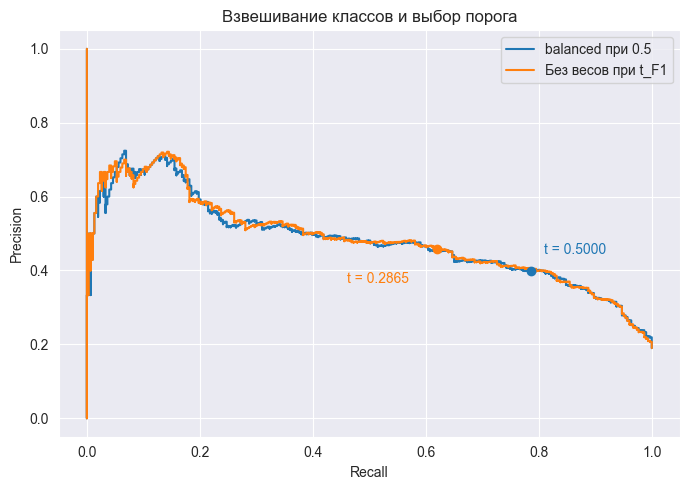

,accuracy,precision,recall,F1,ROC-AUC,PR-AUC (AP)
balanced при 0.5,0.7343,0.3987,0.7855,0.5289,0.8209,0.4811
Без весов при t_F1,0.7882,0.4574,0.6205,0.5266,0.8209,0.4848


In [18]:
operating_models = {
    'balanced при 0.5': (balanced_scores, 0.5),
    'Без весов при t_F1': (wine_scores, t_f1),
}
operating_rows = {}
fig, ax = plt.subplots(figsize=(7, 5))

for name, (scores, threshold) in operating_models.items():
    curve_precision, curve_recall, _ = metrics.precision_recall_curve(y_test, scores)
    line, = ax.step(curve_recall, curve_precision, where='post', label=name)
    row = evaluate_wine(scores, scores >= threshold)
    operating_rows[name] = row
    ax.scatter(row['recall'], row['precision'], color=line.get_color(), zorder=3)
    offset = (10, 12) if threshold == 0.5 else (-65, -24)
    ax.annotate(f't = {threshold:.4f}', (row['recall'], row['precision']),
                xytext=offset, textcoords='offset points', color=line.get_color())

ax.set(xlabel='Recall', ylabel='Precision', title='Взвешивание классов и выбор порога')
ax.legend()
fig.tight_layout()
plt.show()
operating_table = pd.DataFrame.from_dict(operating_rows, orient='index')
display(operating_table.round(4))

PR-кривые близки. AP у balanced равна 0,4811, у модели без весов - 0,4848. При выбранных порогах balanced даёт recall 0,7855 при precision 0,3987, а модель без весов даёт 0,6205 и 0,4574 соответственно. Здесь взвешивание в основном меняет рабочую точку. Оно также меняет коэффициенты и местами меняет порядок объектов, поэтому кривые немного различаются. Изменение порога одной обученной модели двигает точку вдоль её кривой.

### Задание 3.4. Итоги (0.25 балла)

Сведите в одну таблицу все модели частей 2 и 3 (метрики на тестовой выборке). Какую модель и какой порог вы бы предложили сервису из сценария? Обоснуйте выбор, опираясь на метрики.

In [19]:
all_rows = {
    'Всегда 0': evaluate_wine(constant_predictions, constant_predictions),
    'LogReg GD': evaluate_wine(wine_gd_scores, wine_gd.predict(wine_scaler.transform(X_test))),
    **weight_rows,
    'sklearn, без весов, t_F1': operating_rows['Без весов при t_F1'],
    'sklearn, без весов, t_R': evaluate_wine(wine_scores, wine_scores >= t_recall),
    **sampling_rows,
}
all_metrics = pd.DataFrame.from_dict(all_rows, orient='index')
display(all_metrics.round(4))

,accuracy,precision,recall,F1,ROC-AUC,PR-AUC (AP)
Всегда 0,0.8102,0.0000,0.0000,0.0000,0.5000,0.1898
LogReg GD,0.8145,0.5200,0.3003,0.3808,0.8206,0.4838
"sklearn, без весов",0.8152,0.5227,0.3036,0.3841,0.8209,0.4848
"sklearn, balanced",0.7343,0.3987,0.7855,0.5289,0.8209,0.4811
"sklearn, без весов, t_F1",0.7882,0.4574,0.6205,0.5266,0.8209,0.4848
"sklearn, без весов, t_R",0.7600,0.4213,0.7063,0.5277,0.8209,0.4848
RandomUnderSampler,0.7331,0.3959,0.7723,0.5235,0.8206,0.4799
NearMiss(2),0.6466,0.3294,0.8317,0.4719,0.7865,0.4479
RandomOverSampler,0.7331,0.3980,0.7921,0.5298,0.8211,0.4811
SMOTE,0.7350,0.3976,0.7690,0.5242,0.8196,0.4796


Для приложения выбираю логистическую регрессию без весов с порогом $t_R=0,2364$. На валидации она даёт 70,5% recall при максимальной precision среди порогов с recall ≥ 70%. На test получилось 70,6% recall, 42,1% precision и F1 0,5277. На этой тестовой выборке порог выполнил условие по охвату. Сомелье может регулировать строгость подборки в приложении.

### Сохранение модели (0 баллов, нужно для части 4)

Сохраните итоговую модель (весь пайплайн, а не только `LogisticRegression`), выбранный порог и тестовую выборку – они понадобятся в приложении. Допишите ячейку под свою итоговую модель.

Если работаете в Colab, скачайте папку `wine_app/` на свой компьютер (например, заархивируйте её и воспользуйтесь `google.colab.files.download`): приложение запускается локально.

In [20]:
import json
import joblib

app_dir = Path('wine_app')
app_dir.mkdir(exist_ok=True)

final_model = wine_model
final_threshold = t_recall

joblib.dump(final_model, app_dir / 'model.joblib')
(app_dir / 'config.json').write_text(
    json.dumps({'threshold': float(final_threshold)}, indent=2) + '\n',
    encoding='utf-8',
)
X_test.assign(target=y_test).to_csv(app_dir / 'test.csv', index=False)

## <font color="green">Часть 4. Демо-приложение на Streamlit (2.5 балла)</font>

Модель в ноутбуке видите только вы. Чтобы ей мог пользоваться сомелье сервиса (и чтобы он понимал, почему меняется подборка при изменении порога), сделаем небольшое веб-приложение.

[Streamlit](https://docs.streamlit.io/) это библиотека, которая которая превращает обычный Python-скрипт в веб-страницу: каждый вызов вроде `st.slider(...)` или `st.write(...)` рисует элемент интерфейса, а при любом действии пользователя скрипт перезапускается сверху вниз. Минимальный пример:

```python
import streamlit as st

t = st.slider('Порог', 0.0, 1.0, 0.5)
st.write('Вы выбрали порог', t)
```

Приложение запускается **локально**, а не в Colab:

```bash
pip install streamlit
streamlit run app.py
```

Полезные элементы: [`st.number_input`](https://docs.streamlit.io/develop/api-reference/widgets/st.number_input), [`st.slider`](https://docs.streamlit.io/develop/api-reference/widgets/st.slider), [`st.tabs`](https://docs.streamlit.io/develop/api-reference/layout/st.tabs), [`st.file_uploader`](https://docs.streamlit.io/develop/api-reference/widgets/st.file_uploader), [`st.download_button`](https://docs.streamlit.io/develop/api-reference/widgets/st.download_button), [`st.pyplot`](https://docs.streamlit.io/develop/api-reference/charts/st.pyplot), [`st.metric`](https://docs.streamlit.io/develop/api-reference/data/st.metric), [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource) (чтобы не загружать модель заново при каждом перезапуске скрипта).

Приложение `wine_app/app.py` использует файлы, сохранённые в ячейке выше (`model.joblib`, `config.json`, `test.csv`). **Модель внутри приложения не обучается.**

### Задание 4.1. Оценка одного вина (0.5 балла)

Сделайте вкладку, на которой пользователь вводит 12 признаков вина (диапазоны и значения по умолчанию возьмите из данных, например минимум, максимум и медиану по `test.csv`; признак `is_red` – переключатель «красное / белое»). Сделайте сайдбар с интерактивным ползунком значения порога, установите порог по умолчанию значением из файла `config.json`. Приложение показывает вероятность того, что вино хорошее, и решение модели при установленном пороге.

### Задание 4.2. Интерактивная визуализация модельных метрик (0.5 балла)

Сделайте вкладку «Модельные метрики». При изменении порога на тестовой выборке пересчитываются и выводятся:
- матрица ошибок;
- precision, recall и $F_1$;
- ROC- и PR-кривые, на которых отмечена точка, соответствующая текущему порогу.

Добавьте короткий текст для сомелье: что произойдёт с подборкой, если порог увеличить или уменьшить.

### Задание 4.3. Пакетное предсказание (0.5 балла)

Сделайте вкладку, на которой пользователь загружает CSV-файл с признаками вин (без столбца `target`), а приложение показывает таблицу с вероятностью и решением для каждого вина и даёт скачать её через `st.download_button`. Порог для этой вкладки берётся из слайдера задания 4.2 (подсказка: [`st.session_state`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.session_state)) или задаётся отдельно – на ваш выбор.

Приложение не должно падать, если в файле не хватает столбцов: в этом случае выведите понятное сообщение об ошибке (`st.error`).

### Задание 4.4. Что выучила модель (0.25 балла)

Сделайте вкладку с горизонтальной столбчатой диаграммой коэффициентов логистической регрессии (после масштабирования признаков), отсортированных по значению. Подпишите, какие признаки сильнее всего «голосуют» за хорошее вино, а какие – против.

### Задание 4.5. Кэширование (0.25 балла)

Streamlit выполняет `app.py` заново при каждом действии пользователя: сдвинули слайдер порога – скрипт отработал сверху вниз ещё раз. Без кэширования при каждом движении слайдера модель снова читается с диска, а вероятности на тестовой выборке пересчитываются, хотя от порога они не зависят.

1. Модель загружается функцией с декоратором [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource): один объект на весь сервер. Путь к файлу строится от папки, где лежит `app.py` (`Path(__file__).parent`), а не от текущей директории.
2. `test.csv` читается функцией с декоратором [`st.cache_data`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_data).
3. Вероятности класса 1 на тестовой выборке считаются один раз, в функции с `st.cache_data`. При движении слайдера в задании 4.2 меняется только сравнение с порогом, `predict_proba` заново не вызывается. Подсказка: аргумент, который Streamlit не должен хешировать (например, модель), называют с подчёркиванием в начале: `def test_proba(_model, X): ...`.

Ответьте в `README.md` или в комментарии в `app.py`: почему для модели используется `st.cache_resource`, а для таблиц – `st.cache_data`? Что изменится, если вызвать `joblib.load` без декоратора?

Использование `joblib.load` без декоратора или загрузка модели через `st.cache_data` за этот пункт не засчитываются.

### Задание 4.6. Оформление и сдача (0.5 балла)

1. Сдайте папку `wine_app/` (архивом или укажите в клетке ниже ссылку на Github репозиторий) со следующим содержимым:
- `app.py`;
- `model.joblib`, `config.json`, `test.csv`;
- `requirements.txt` с версиями библиотек, при которых приложение запускается;
- `README.md`: инструкция о том, как запустить приложение с указанием версии Python интерпретатора.

2. Проведите деплой приложения на [Streamlit Community Cloud](https://streamlit.io/cloud).

**Опишите общие мысли о работе. Это место для вашей рефлексии – необязательное, но полезное.** 🍷